In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Reading Transformed Stock Data for Portfolio

In [2]:
# Reading Log Returns for Each Asset and the Interest Rates for the Credit

# STOCK DATA
portfolio_df = pd.read_csv("_portfolio_returns.csv", index_col=["Date"]).drop(columns=["EUR_USD"])
# portfolio_df = portfolio_df.drop(columns=["EUR_USD"]) # For now just drop, need answer to Q1
# portfolio_df = portfolio_df*(-1)      # Converting into Loss Distribution. instead of P/L, IT IS THAT SIMPLE RIGHT?

# Reading Rates for Credit
euribor = pd.read_csv("_EURIBOR_monthly_rates.csv", index_col=["Date"])
# ...       # Nothing for now, need answer to Q2

# Declaring weights for portfolio construction, DON'T FORGET TO UPDAtE ONCE CREDIT IS ADDED
PORTFOLIO_WEIGHTS= np.array([0.15, 0.2, 0.15, 0.15, 0.15, 0.2])     # If we short something we can get more cash to invest

## QUESTIONS: 
### SHOULD WE JUST CONVERT EACH DAY TO EURO RETURNS? ARE WE EXPOSED EVERY DAY? THAT IS THE POINT RIGHT? OR ONLY ON BUY/SELL DAYS AND COMPARE? - No it is integrated into weights``
### I HAVE NO IDEA HOW TO CALCULATE RETURNS/LOSES ON CREDIT. HOW IS IT DONE GIVEN RATES?
### JUST MULTIPLY BY -1 TO GET LOSS DISTRIBUTION. IT IS JUST FOR THE CONVENTION RIGHT? NO REAL DIFFERENCE?
### QQPLOT MUST HAVE A LINE=Q, WHICH GOES THROUGH QUANTILES, NOT JUST 45 DEGREEES? IT DOES NOT MAKE MUCH SENSE, AS IT IS OBVIOUSLY IS NOT STANDARD NORMAL DISTRIBUTION, CORRECT?
### DO WE CALCULATE RETURNS PROPERLY? WE USE LOG RETURNS.
### SHOULD WE JUST DROP ZEROS FROM NON-TRADING DAYS FOR THE VISUALIZATION?

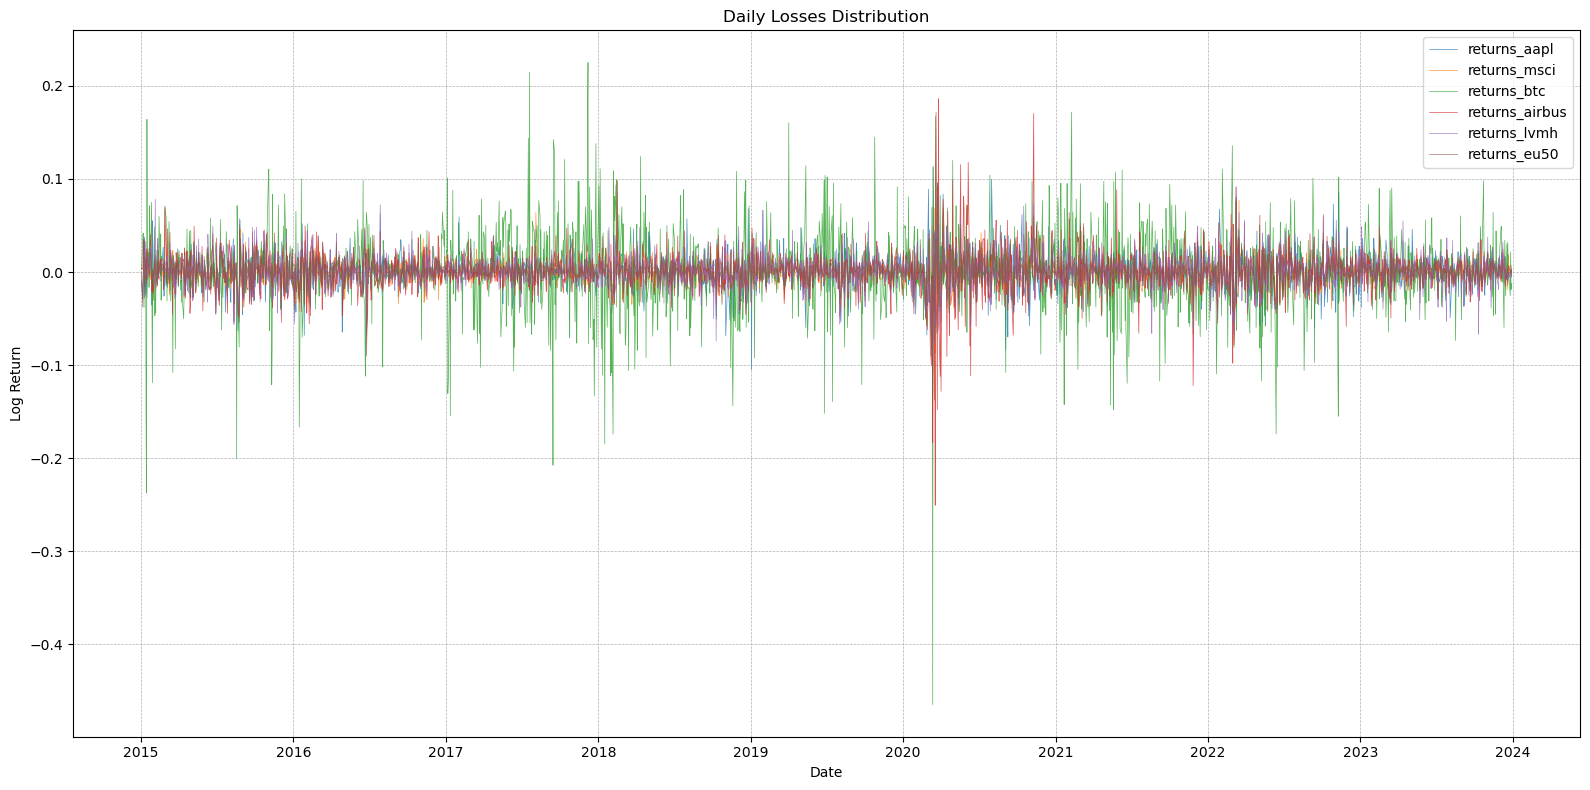

In [3]:
# Plotting
plt.figure(figsize=(16, 8))
portfolio_df.index = pd.to_datetime(portfolio_df.index)       # Making sure matplotlib recognizes the datetime index

for column in portfolio_df.columns:
    plt.plot(portfolio_df.index, portfolio_df[column], lw=.5, alpha=0.8, label=column)

# Setting the x-axis to only show years
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.legend()
plt.title('Daily Losses Distribution')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()


# Value-at-Risk and Expected Shortfall with Variance-CoVariance method

### Functions that are necessary for all methods

In [4]:
window_size = 250
data = portfolio_df

rolling_vol: pd.DataFrame = data.rolling(window = window_size).std(ddof = 0).dropna()

$$
\hat{\sigma}_t^2=\frac{1}{n}\sum_{j=0}^{n-1}x_{t-j}^2
$$

In [5]:
from typing import Callable, Any

def PortRet(*, data: pd.DataFrame, weights: np.array) -> pd.DataFrame:

    assert np.sum(weights) == 1
    return data @ weights

def VCV(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def VCE(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return -1 * Vol * p / (1 - alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return -1 * Vol * ((df + (q ** 2)) / (df - 1)) * p / (1 - alpha)
        case _:
            raise NotImplementedError()    


In [6]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        sig[t+1] = omega + alpha *  x[t]**2 + beta * sig[t]

    return sig ** .5

def VCV_ES_GARCH(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr()
    n: int = CM.shape[0]
    W = weights.reshape((n, 1)) * weights.reshape((1,6))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
    
    vol = []
    Sigm = vol_df.values
    for row in Sigm:
        vol.append(row @ CMU @ row)

    return np.array(vol) ** .5

def VCVG(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)

In [7]:
portfolio_sliced = portfolio_df[250:]
GARCH = VCV_ES_GARCH(portfolio_sliced, weights = PORTFOLIO_WEIGHTS)

In [8]:
VaR_data_norm = VCV(portfolio_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.norm.ppf)
VaR_data_t_df4 = VCV(portfolio_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 4)
VaR_data_t_df5 = VCV(portfolio_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 5)
VaR_data_t_df6 = VCV(portfolio_df, window_size = window_size, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 6)
VaR_data_GARCH = VCVG(GARCH, alpha = .05, dist = stats.norm.ppf)

In [9]:
ES_data_norm = VCE(VaR_data_norm.Vol, alpha = .05, dist = stats.norm)
ES_data_t_df4 = VCE(VaR_data_t_df4.Vol, alpha = .05, dist = stats.t, df = 4)
ES_data_t_df5 = VCE(VaR_data_t_df5.Vol, alpha = .05, dist = stats.t, df = 5)
ES_data_t_df6 = VCE(VaR_data_t_df6.Vol, alpha = .05, dist = stats.t, df = 6)
ES_data_GARCH = VCE(GARCH, alpha = .05, dist = stats.norm)

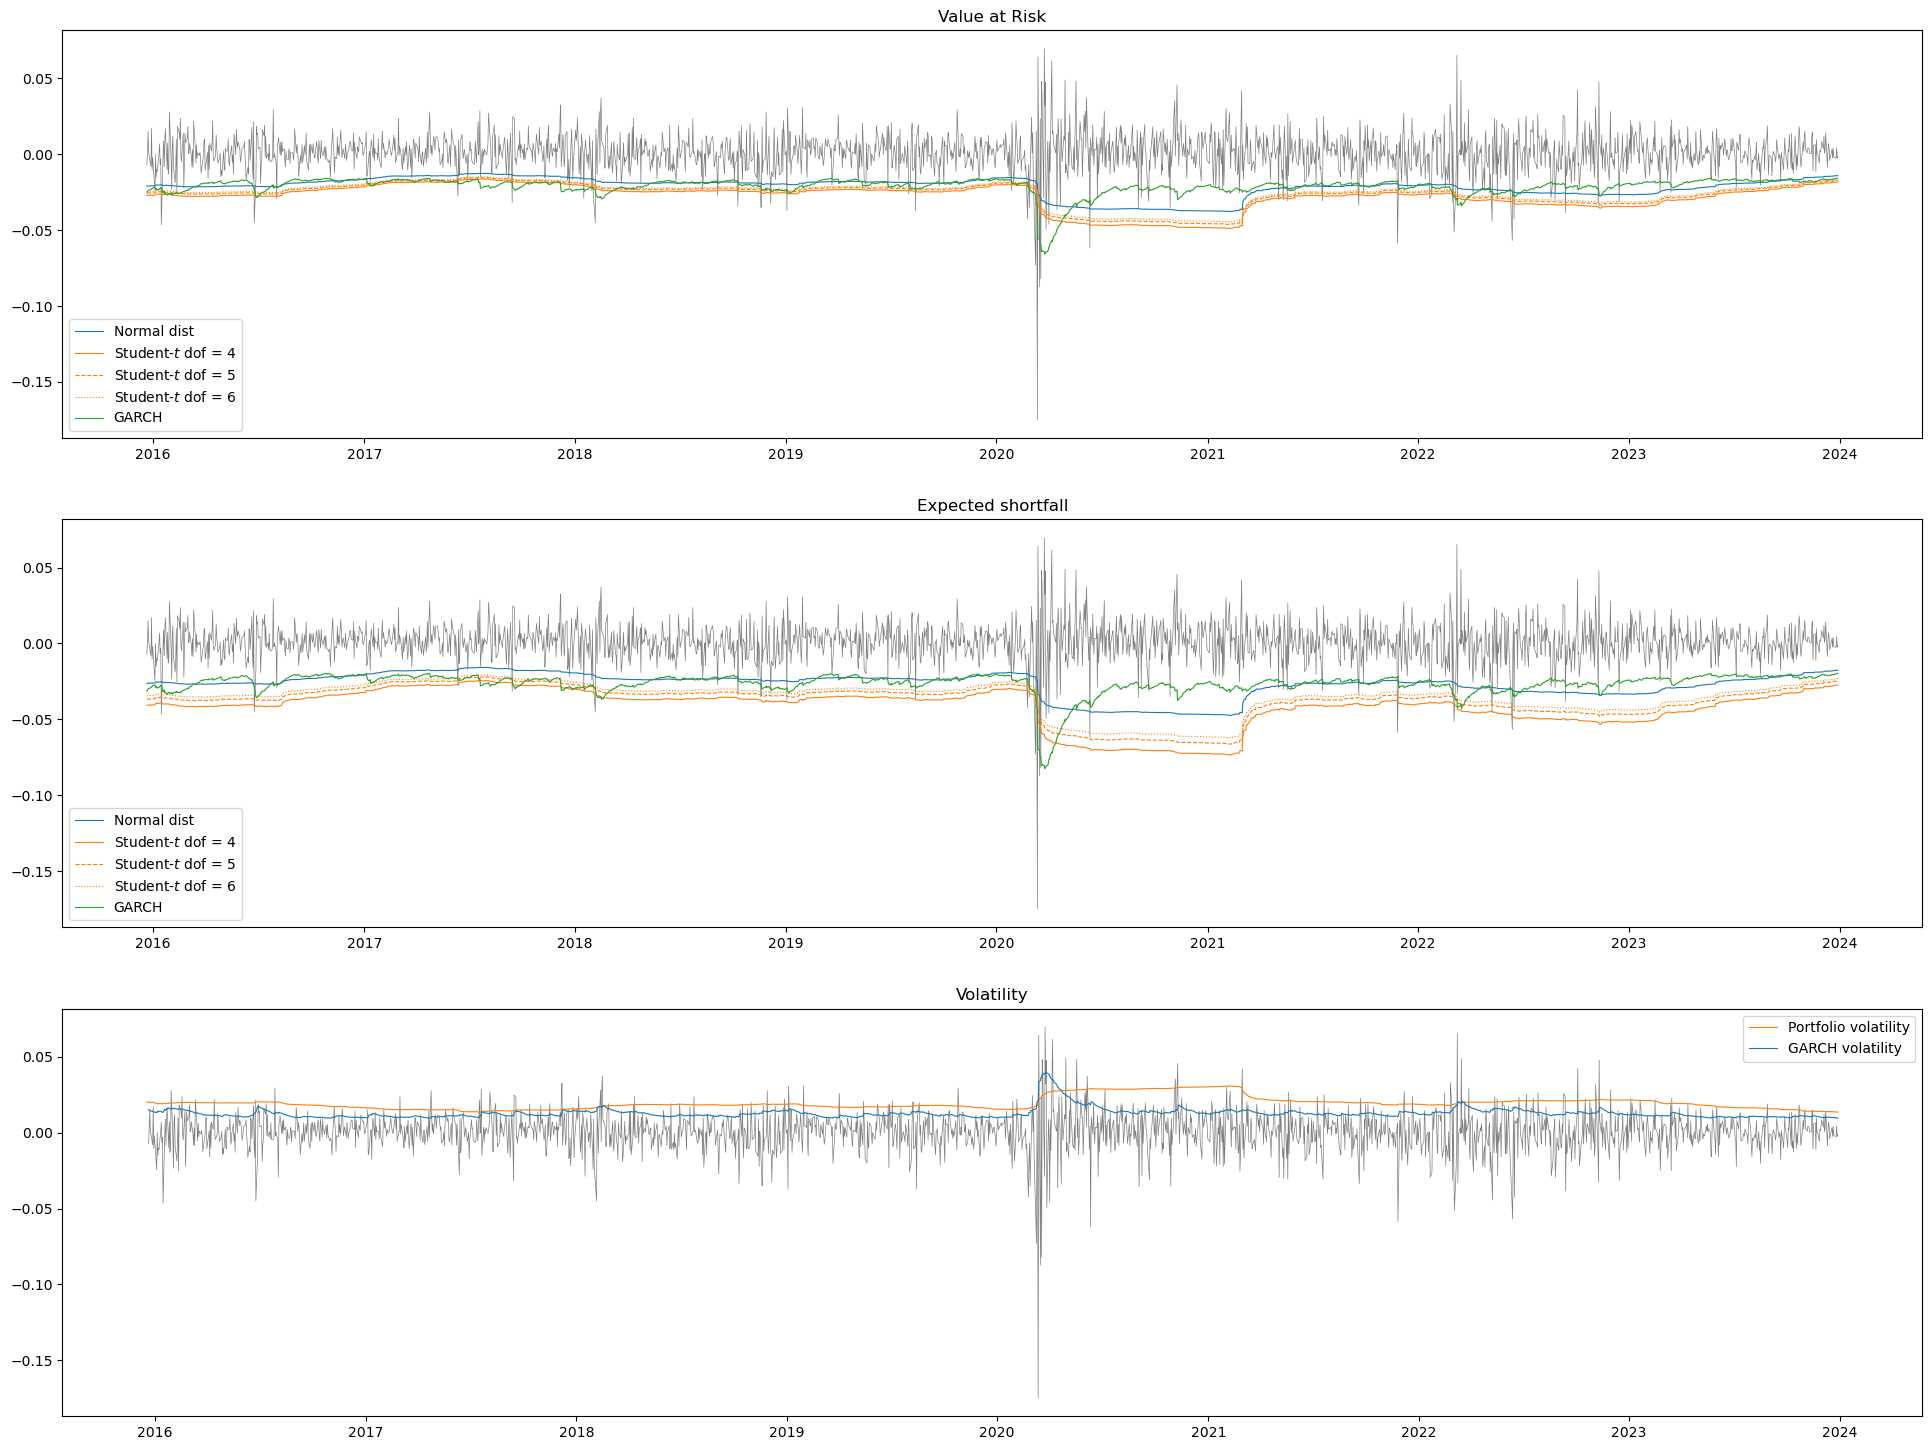

In [10]:
fig, axs = plt.subplots(3, 1, figsize = (24, 18))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(ES_data_norm, label = 'Normal dist', lw = .8)
axs[1].plot(ES_data_t_df4, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1].plot(ES_data_t_df5, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1].plot(ES_data_t_df6, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(VaR_data_norm.VaR, label = 'Normal dist', lw = .8)
axs[0].plot(VaR_data_t_df4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0].plot(VaR_data_t_df5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0].plot(VaR_data_t_df6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
axs[0].plot(portfolio_sliced.index, VaR_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
axs[0].legend()

axs[2].set_title('Volatility')
axs[2].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[2].plot(rolling_vol.index, rolling_vol.values @ PORTFOLIO_WEIGHTS, c = 'C1', lw = .8, label = 'Portfolio volatility')
axs[2].plot(portfolio_sliced.index, GARCH, c = 'C0', lw = .8, label = 'GARCH volatility')
axs[2].legend()
plt.show()

In [11]:
def VCHS(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    portfolio_returns = PortRet(data = data, weights = port_weights)
    
    df = pd.DataFrame([], index = data.index, columns = ['VaR'])
    VaR = portfolio_returns.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(data)):
        _ = data.iloc[k - window_size: k]
        _ = _[_ < VaR.iloc[k]]
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

In [12]:
VAR_ES = VCHS(portfolio_df, window_size, PORTFOLIO_WEIGHTS, .05)

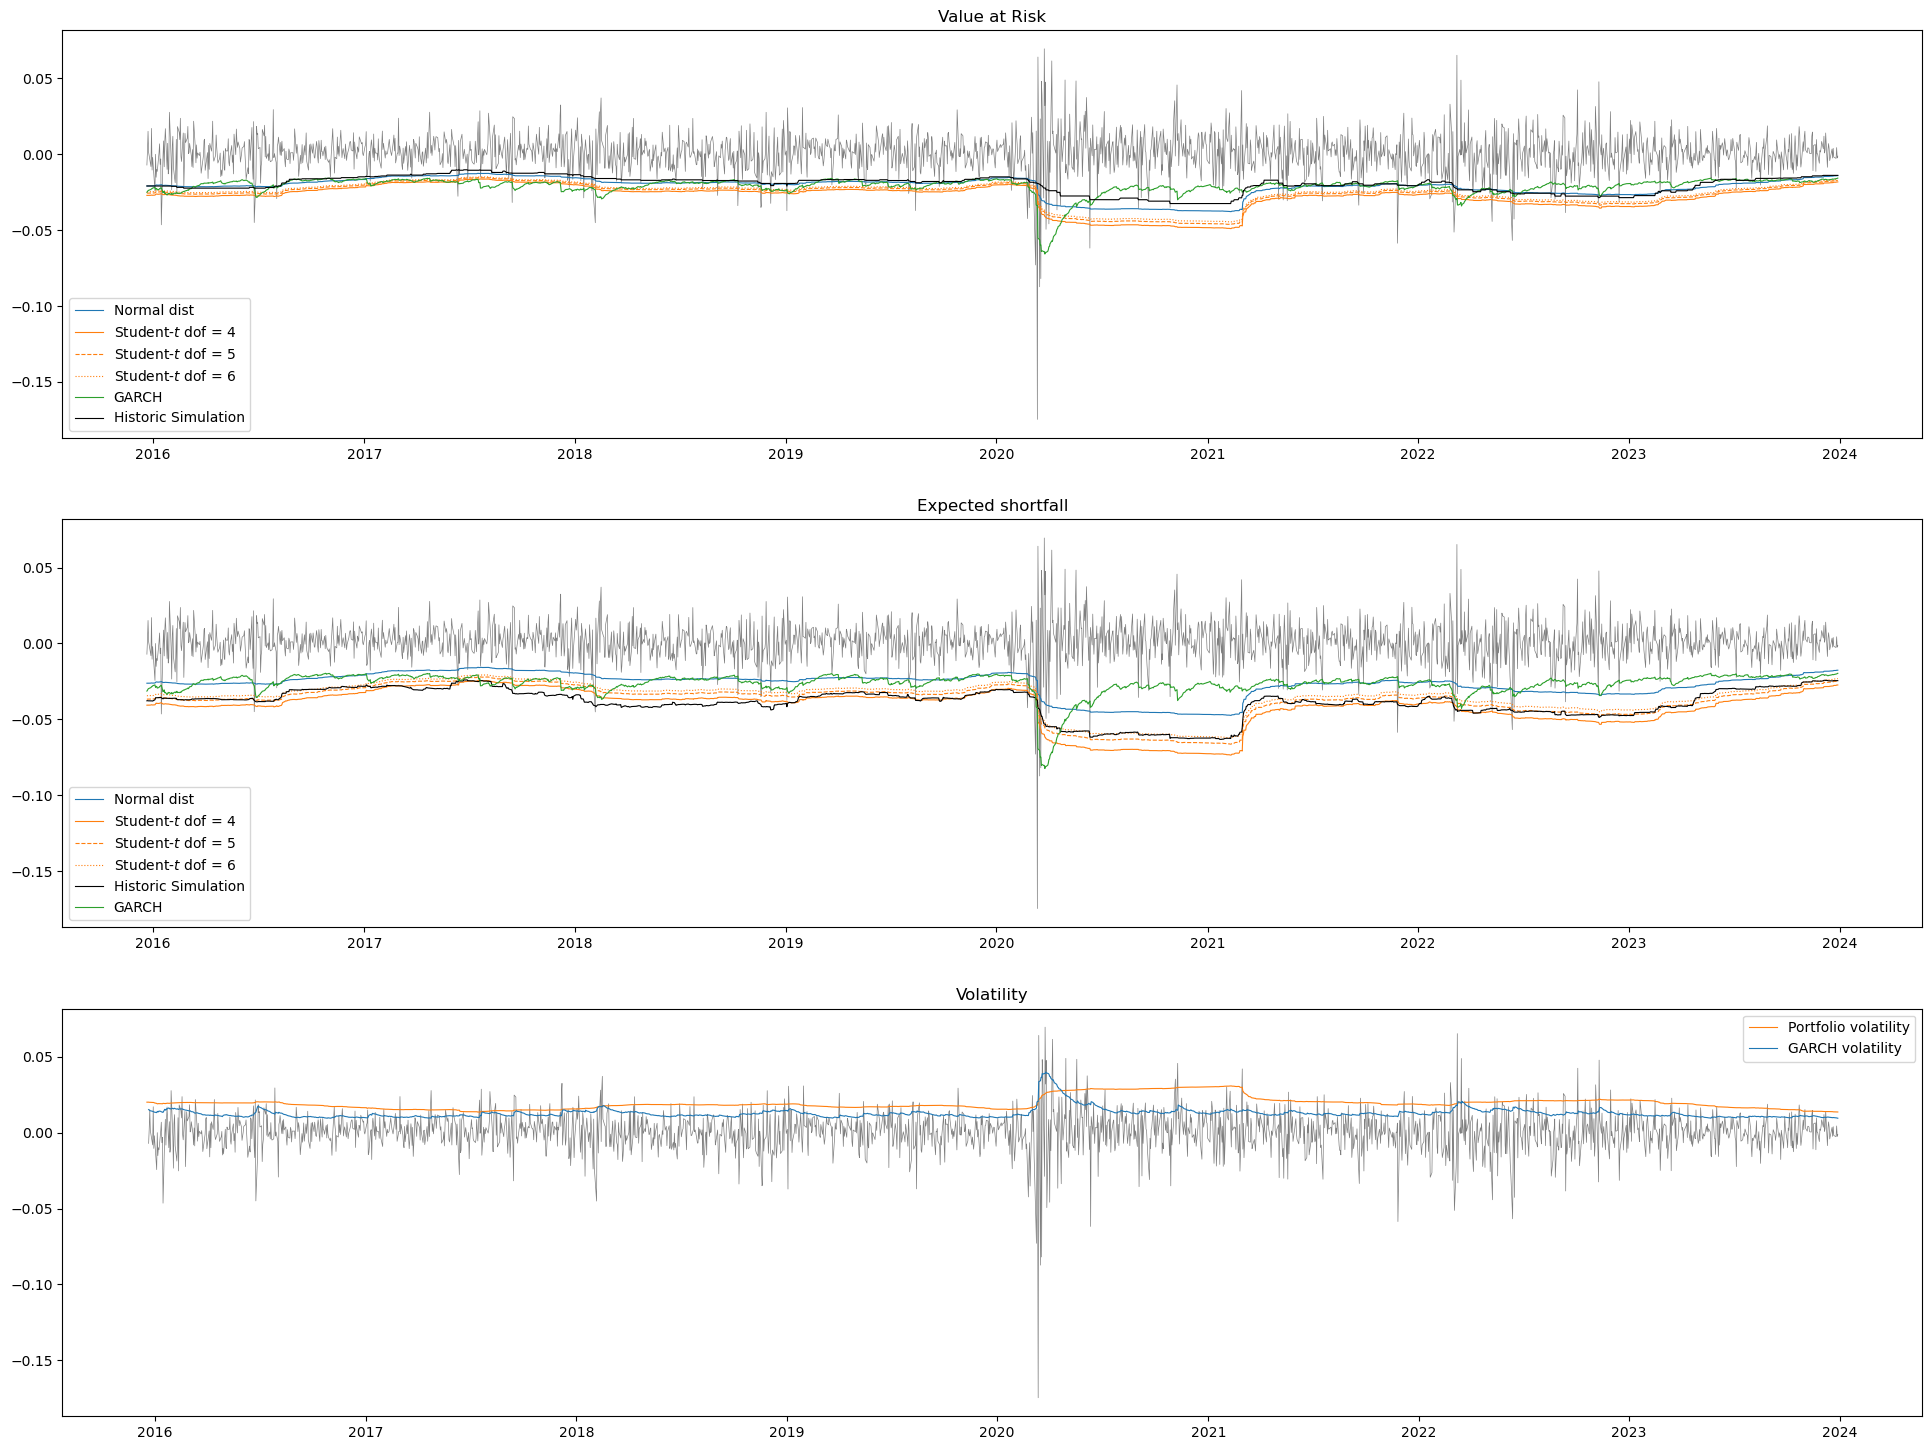

In [13]:
fig, axs = plt.subplots(3, 1, figsize = (24, 18))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(ES_data_norm, label = 'Normal dist', lw = .8)
axs[1].plot(ES_data_t_df4, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1].plot(ES_data_t_df5, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1].plot(ES_data_t_df6, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
axs[1].plot(VAR_ES.ES, label = 'Historic Simulation', c = 'black', ls = '-', lw = .8)
axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(VaR_data_norm.VaR, label = 'Normal dist', lw = .8)
axs[0].plot(VaR_data_t_df4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0].plot(VaR_data_t_df5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0].plot(VaR_data_t_df6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
axs[0].plot(portfolio_sliced.index, VaR_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
axs[0].plot(VAR_ES.VaR, label = 'Historic Simulation', c = 'black', ls = '-', lw = .8)
axs[0].legend()

axs[2].set_title('Volatility')
axs[2].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[2].plot(rolling_vol.index, rolling_vol.values @ PORTFOLIO_WEIGHTS, c = 'C1', lw = .8, label = 'Portfolio volatility')
axs[2].plot(portfolio_sliced.index, GARCH, c = 'C0', lw = .8, label = 'GARCH volatility')
axs[2].legend()
plt.show()

In [14]:
def filtered_HS(data, weights):
    for col in data.copy().columns:
        x = data[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        data[f'Vol {col}'] = volatility(omega, alpha, beta, x)

    return data

In [15]:
test = filtered_HS(portfolio_df, 0)

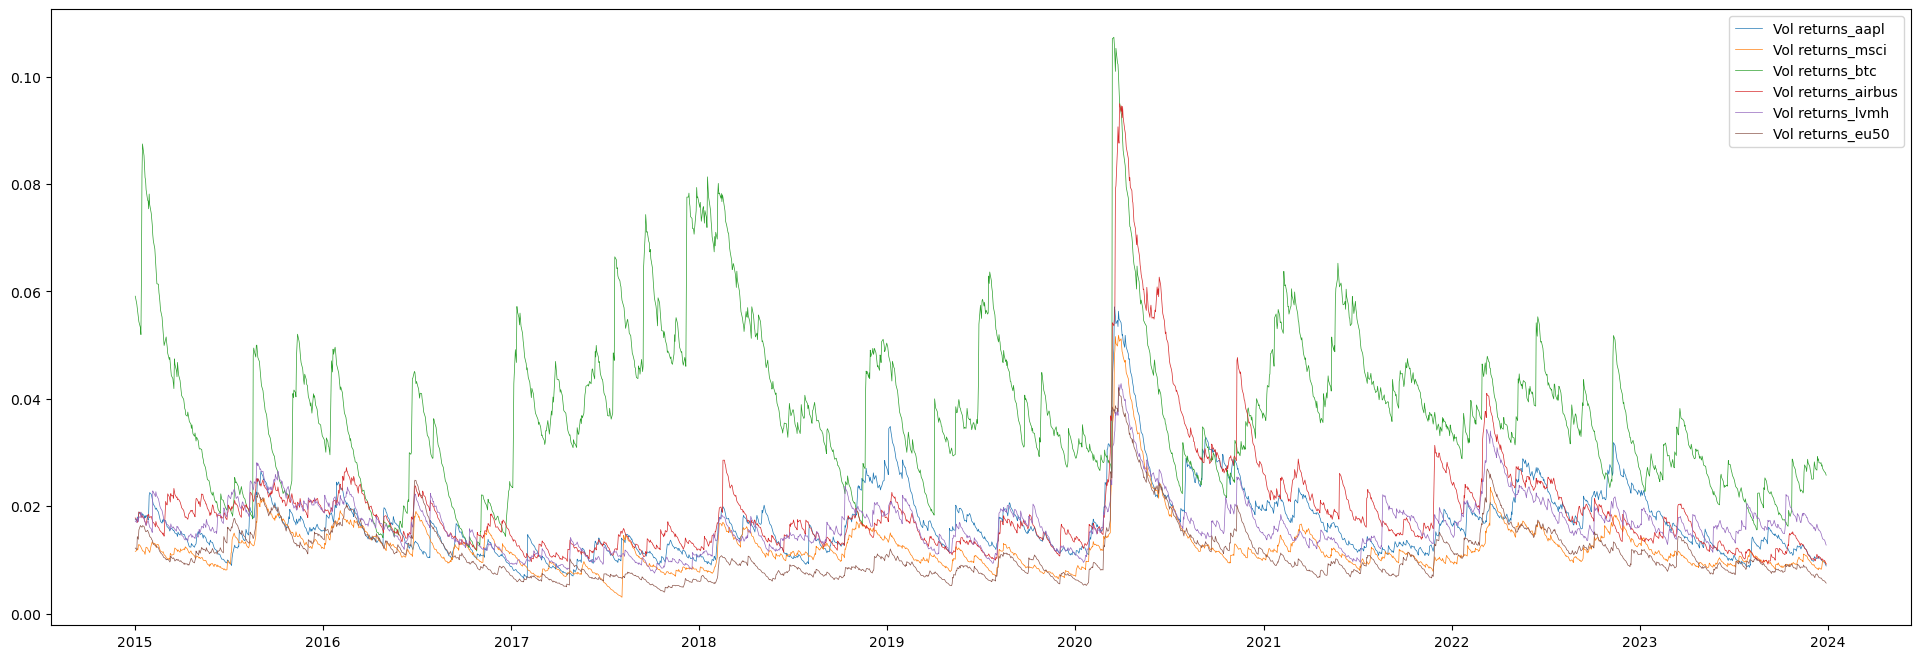

In [16]:
plt.rcParams['figure.figsize'] = (24, 8)
plt.plot(test.T[6:].T, lw = .5, label = test.T[6:].T.columns)
plt.legend()
plt.show()

In [17]:
test

,returns_aapl,returns_msci,returns_btc,returns_airbus,returns_lvmh,returns_eu50,Vol returns_aapl,Vol returns_msci,Vol returns_btc,Vol returns_airbus,Vol returns_lvmh,Vol returns_eu50
Date,,,,,,,,,,,,
2015-01-02,-0.009558,-0.014620,0.002489,0.004223,-0.010643,0.000000,0.017597,0.011596,0.059109,0.017831,0.017243,0.012222
2015-01-05,-0.028576,-0.017637,0.038169,0.003006,-0.029471,-0.037808,0.017284,0.011766,0.057615,0.017405,0.016974,0.011913
2015-01-06,0.000094,-0.005732,0.041796,0.022905,-0.011479,-0.007462,0.018017,0.012127,0.056801,0.016978,0.017808,0.014363
2015-01-07,0.013925,0.022415,0.028073,0.025714,0.000796,0.007727,0.017561,0.011889,0.056146,0.017322,0.017546,0.014098
2015-01-08,0.037703,0.017348,-0.038046,0.033509,0.030940,0.034898,0.017397,0.012626,0.055083,0.017836,0.017103,0.013850
...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-22,-0.005563,-0.005324,0.002931,0.006620,-0.007697,-0.001098,0.009726,0.009855,0.027034,0.010037,0.013942,0.006231
2023-12-26,-0.002845,0.007779,-0.025374,0.000000,0.000000,0.000000,0.009561,0.009679,0.026357,0.009894,0.013697,0.006078
2023-12-27,0.000518,0.005965,0.021462,-0.000143,-0.003123,0.002195,0.009340,0.009593,0.026309,0.009644,0.013350,0.005924


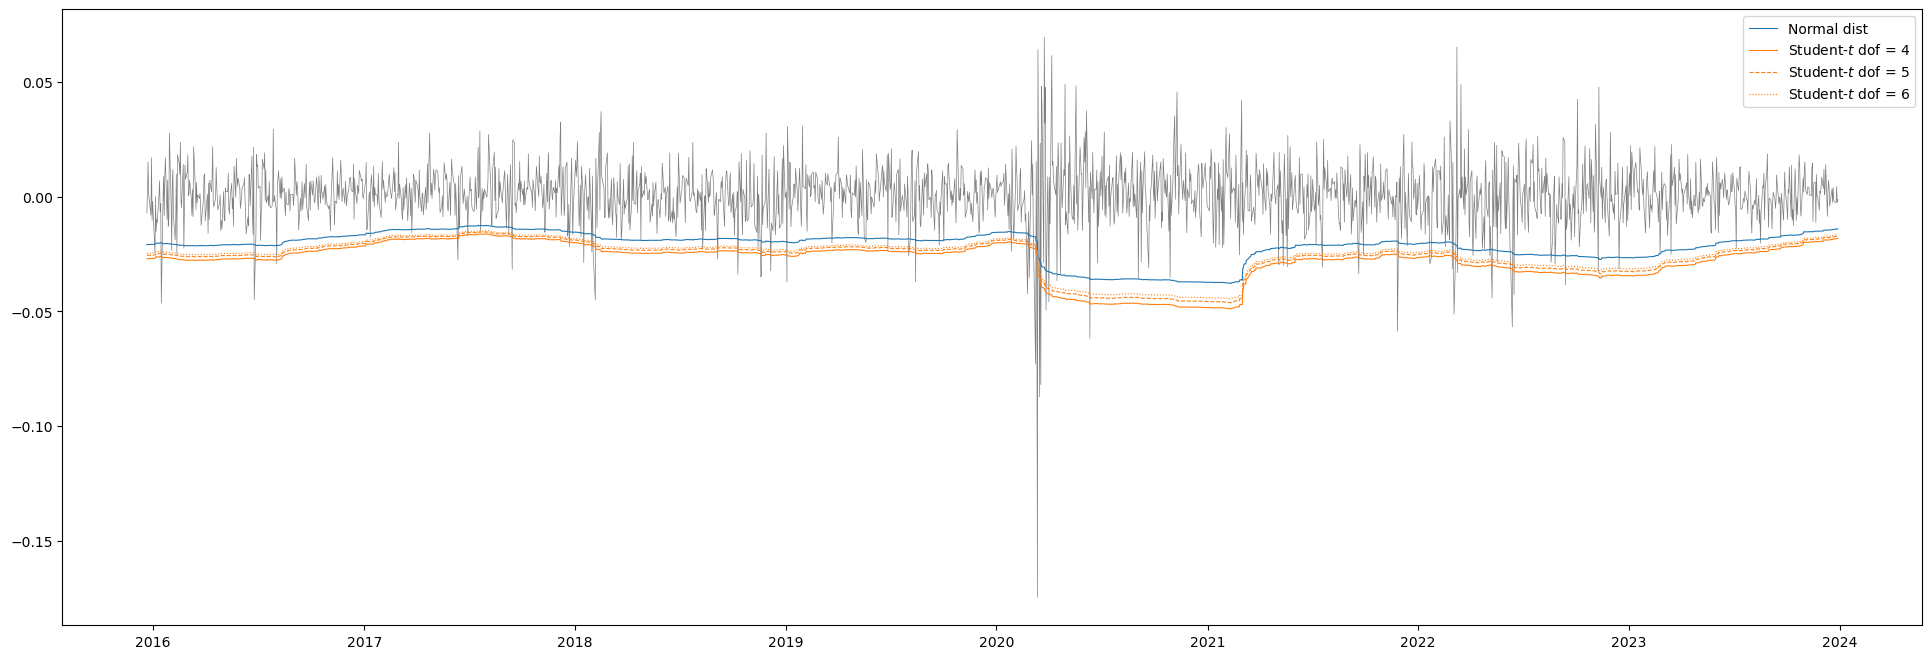

In [18]:
plt.rcParams['figure.figsize'] = (24, 8)
plt.plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
plt.plot(VaR_data_norm.VaR, label = 'Normal dist', lw = .8)
plt.plot(VaR_data_t_df4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
plt.plot(VaR_data_t_df5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
plt.plot(VaR_data_t_df6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
plt.legend()
plt.show()

In [19]:
def calculate_var_normal(annual_volatility, mean_return, z_score):
    """
    Calculate the Value at Risk (VaR) using the Normal distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - z_score (float): The Z-score corresponding to the desired confidence level.

    Returns:
    - float: The calculated VaR.
    """
    return mean_return + z_score * annual_volatility

def calculate_var_student_t(annual_volatility, mean_return, t_critical_value, degrees_of_freedom):
    """
    Calculate the Value at Risk (VaR) using Student's T-distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - t_critical_value (float): The critical value from the T-distribution corresponding to the desired confidence level.
    - degrees_of_freedom (int): The degrees of freedom for the T-distribution.

    Returns:
    - float: The calculated VaR adjusted for the fat tails of the T-distribution.
    """
    adjusted_volatility = annual_volatility / np.sqrt(degrees_of_freedom / (degrees_of_freedom - 2))
    return mean_return + t_critical_value * adjusted_volatility

def calculate_es_normal(annual_volatility, mean_return, z_score, confidence_level):
    """
    Calculate the Expected Shortfall (ES) using the Normal distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - z_score (float): The Z-score corresponding to the desired confidence level.
    - confidence_level (float): The confidence level as a decimal (e.g., 0.95 for 95%).

    Returns:
    - float: The calculated ES.
    """
    density_at_z = stats.norm.pdf(z_score)
    return (density_at_z / (1 - confidence_level)) * annual_volatility + mean_return

def calculate_es_student_t(annual_volatility, mean_return, t_critical_value, degrees_of_freedom, confidence_level):
    """
    Calculate the Expected Shortfall (ES) using Student's T-distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - t_critical_value (float): The critical value from the T-distribution corresponding to the desired confidence level.
    - degrees_of_freedom (int): The degrees of freedom for the T-distribution.
    - confidence_level (float): The confidence level as a decimal (e.g., 0.95 for 95%).

    Returns:
    - float: The calculated ES adjusted for the fat tails of the T-distribution.
    """
    adjusted_volatility = annual_volatility / np.sqrt(degrees_of_freedom / (degrees_of_freedom - 2))
    density_at_t = stats.t.pdf(t_critical_value, degrees_of_freedom)
    return (density_at_t / (1 - confidence_level)) * ((degrees_of_freedom + t_critical_value**2) / (degrees_of_freedom - 1)) * adjusted_volatility + mean_return

def calculate_portfolio_risk_metrics(weight_vector, log_losses, distribution_method="Normal", degrees_of_freedom=1):
    """
    Calculate Value at Risk (VaR) and Expected Shortfall (ES) for a portfolio using either
    Normal or Student's t-distribution methods.

    Parameters:
    - weight_vector (np.array): The weight of each asset in the portfolio.
    - log_losses (np.array): Logarithmic losses of the assets in the portfolio.
    - distribution_method (str): Specifies the distribution method to use for calculating VaR and ES. 
      Accepts "Normal" for Normal distribution or "Student" for Student's t-distribution.
    - degrees_of_freedom (int): The degrees of freedom for the Student's t-distribution. 
      This parameter is ignored if distribution_method is "Normal".

    Returns:
    - tuple: A tuple containing the calculated VaR and ES values at 97.5% and 99% confidence levels (Four Floats Overall: VaR_975, VaR_99, ES_975, ES_99).
    """

    # Estimate Variance-Covariance matrix of portfolio returns
    covariance_matrix = np.cov(log_losses, rowvar=False)

    # Calculate portfolio volatility
    portfolio_volatility = np.sqrt(weight_vector.T @ covariance_matrix @ weight_vector)
    # Assuming mean return (mu) is zero for a short horizon
    mean_return = 0

    # Initialize variables for clarity
    VaR_975, VaR_99, ES_975, ES_99 = 0, 0, 0, 0

    # Calculate VaR and ES based on the specified distribution method
    if distribution_method == "Normal":
        # Z-scores for 97.5% and 99% confidence intervals for Normal distribution
        z_975, z_99 = 1.96, 2.33
        VaR_975 = calculate_var_normal(portfolio_volatility, mean_return, z_975)
        VaR_99 = calculate_var_normal(portfolio_volatility, mean_return, z_99)
        ES_975 = calculate_es_normal(portfolio_volatility, mean_return, z_975, 0.975)
        ES_99 = calculate_es_normal(portfolio_volatility, mean_return, z_99, 0.99)
    elif distribution_method == "Student":
        # Critical t-values for 97.5% and 99% confidence intervals for Student's t-distribution
        t_975 = stats.t.ppf(0.975, degrees_of_freedom)
        t_99 = stats.t.ppf(0.99, degrees_of_freedom)
        VaR_975 = calculate_var_student_t(portfolio_volatility, mean_return, t_975, degrees_of_freedom)
        VaR_99 = calculate_var_student_t(portfolio_volatility, mean_return, t_99, degrees_of_freedom)
        ES_975 = calculate_es_student_t(portfolio_volatility, mean_return, t_975, degrees_of_freedom, 0.975)
        ES_99 = calculate_es_student_t(portfolio_volatility, mean_return, t_99, degrees_of_freedom, 0.99)

    return VaR_975, VaR_99, ES_975, ES_99


## Normal Distribution Assumption

In [20]:
# Dropping Volatility from the Dataframe as it is not needed for these methods

portfolio_df = portfolio_df[['returns_aapl', 'returns_msci', 'returns_btc', 'returns_airbus', 'returns_lvmh', 'returns_eu50']]
portfolio = portfolio_df.to_numpy()     # Only returns
portfolio_weighted = portfolio_df.dot(PORTFOLIO_WEIGHTS)

In [21]:
# Obtaining Correct window of Year Size

dates = portfolio_df.index
indexes_where_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_where_year_changes.append(i+1)
print("Indexes where year changes: ", indexes_where_year_changes)

Indexes where year changes:  [258, 516, 774, 1032, 1290, 1549, 1808, 2066]


In [22]:
N = portfolio_df.shape[1]               # Number of Assets in the Portfolio
T = portfolio_df.shape[0]  # Number of Observations

rolling_window = 258     # So that we can see how VaR/ES changes through time, with/without stress periods (COVID in 2020)
# Calculating VaR/ES
VarCovN_VaR_975 = np.zeros(T-rolling_window)
VarCovN_VaR_99 = np.zeros(T-rolling_window)
VarCovN_ES_975 = np.zeros(T-rolling_window)
VarCovN_ES_99 = np.zeros(T-rolling_window)
for i in range(T-rolling_window):
  (VarCovN_VaR_975[i], VarCovN_VaR_99[i], VarCovN_ES_975[i], VarCovN_ES_99[i]) = calculate_portfolio_risk_metrics(PORTFOLIO_WEIGHTS, portfolio[i:rolling_window+i,:], "Normal")

### Visualizing Normal Distribution Assumption per each Asset in the Portfolio

In [23]:
# # We are not keeping QQplots for each asset

# # QQ-Plot to see if asset returns follow normal distribution
# for i in range(N):
#     sm.qqplot(portfolio[:,i], line="q")     # IS LINE=Q OR LINE=R OR LINE 45? Q3
#     plt.title(portfolio_df.columns[i])

In [24]:
# ## We are not keeping Histograms for each asset

# #Histogram of Asset Losses to see the Distribution outline
# for i in range(N):
#     plt.figure(figsize=(12, 8))
#     plt.title(portfolio_df.columns[i])
#     plt.hist(portfolio[:,i], bins=100, density=True)
#     plt.show()

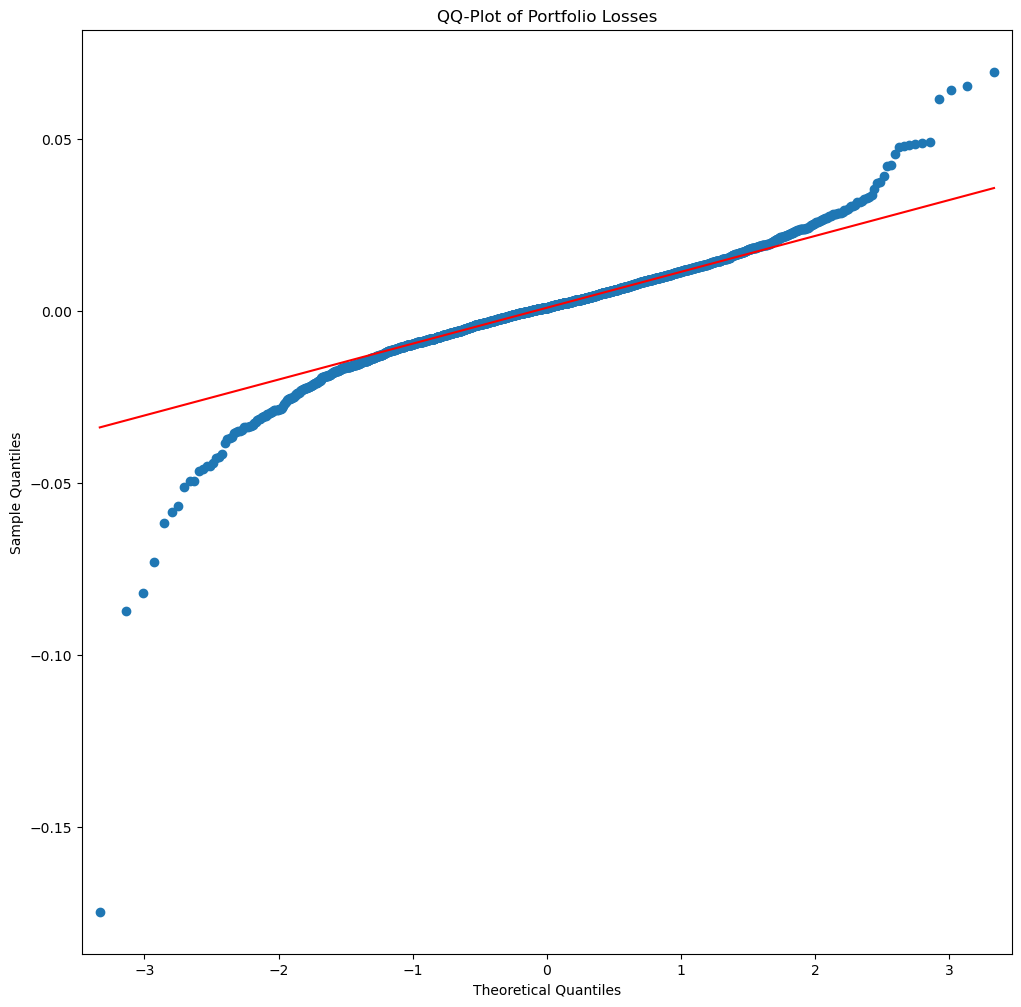

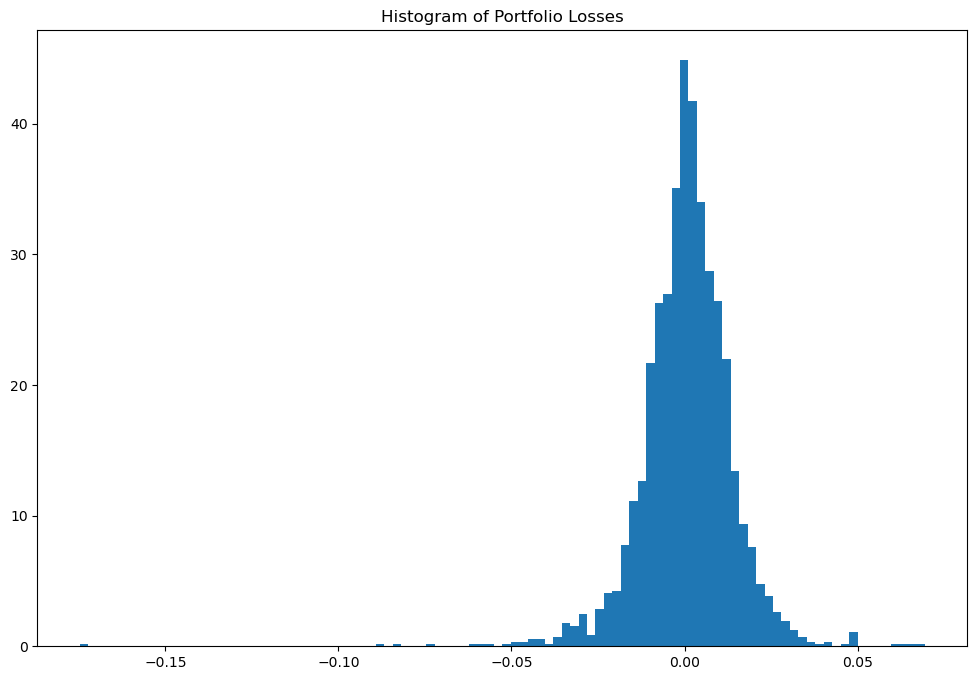

In [25]:
# QQ-Plot and Historgram on Portfolio Level

#QQ-plot
plt.figure(figsize=(12, 12))
plt.title("QQ-Plot of Portfolio Losses")
sm.qqplot(portfolio_weighted, dist=stats.norm, line="q", ax=plt.subplot(1,1,1))
plt.show()

#Histogram
plt.figure(figsize=(12, 8))
plt.hist(portfolio_weighted, bins=100, density=True)
plt.title("Histogram of Portfolio Losses")
plt.show()

## t-Student Distribution Assumption

In [26]:
##Perform Student-t Var-Cov method
degrees_of_freedom = np.array([3, 4, 5, 6])
VarCovT_VaR_975= np.zeros((T-rolling_window, len(degrees_of_freedom)))
VarCovT_VaR_99= np.zeros((T-rolling_window, len(degrees_of_freedom)))
VarCovT_ES_975= np.zeros((T-rolling_window, len(degrees_of_freedom)))
VarCovT_ES_99= np.zeros((T-rolling_window, len(degrees_of_freedom)))
for i in range(T-rolling_window):
  (VarCovT_VaR_975[i,:], VarCovT_VaR_99[i,:], VarCovT_ES_975[i,:], VarCovT_ES_99[i,:]) = calculate_portfolio_risk_metrics(PORTFOLIO_WEIGHTS, portfolio[i:rolling_window+i,:], "Student", degrees_of_freedom)

### Visualizing t-Student Distribution Assumption per each Asset in the Portfolio

In [27]:
# #QQ-plot of historical asset returns to assess validity of Student-t approximation
# for i in range(N):
#     j = 1
#     fig = plt.figure(figsize=(16,16))
#     plt.suptitle(str(portfolio_df.columns[i]))
#     for d in degrees_of_freedom:
#         sm.qqplot(portfolio[:,i], dist=stats.t, distargs=(d,), line="q", ax=plt.subplot(2,2,j))
#         plt.subplot(2,2,j).title.set_text('Degree of Freedom: ' + str(d))
#         j += 1
#     plt.show()

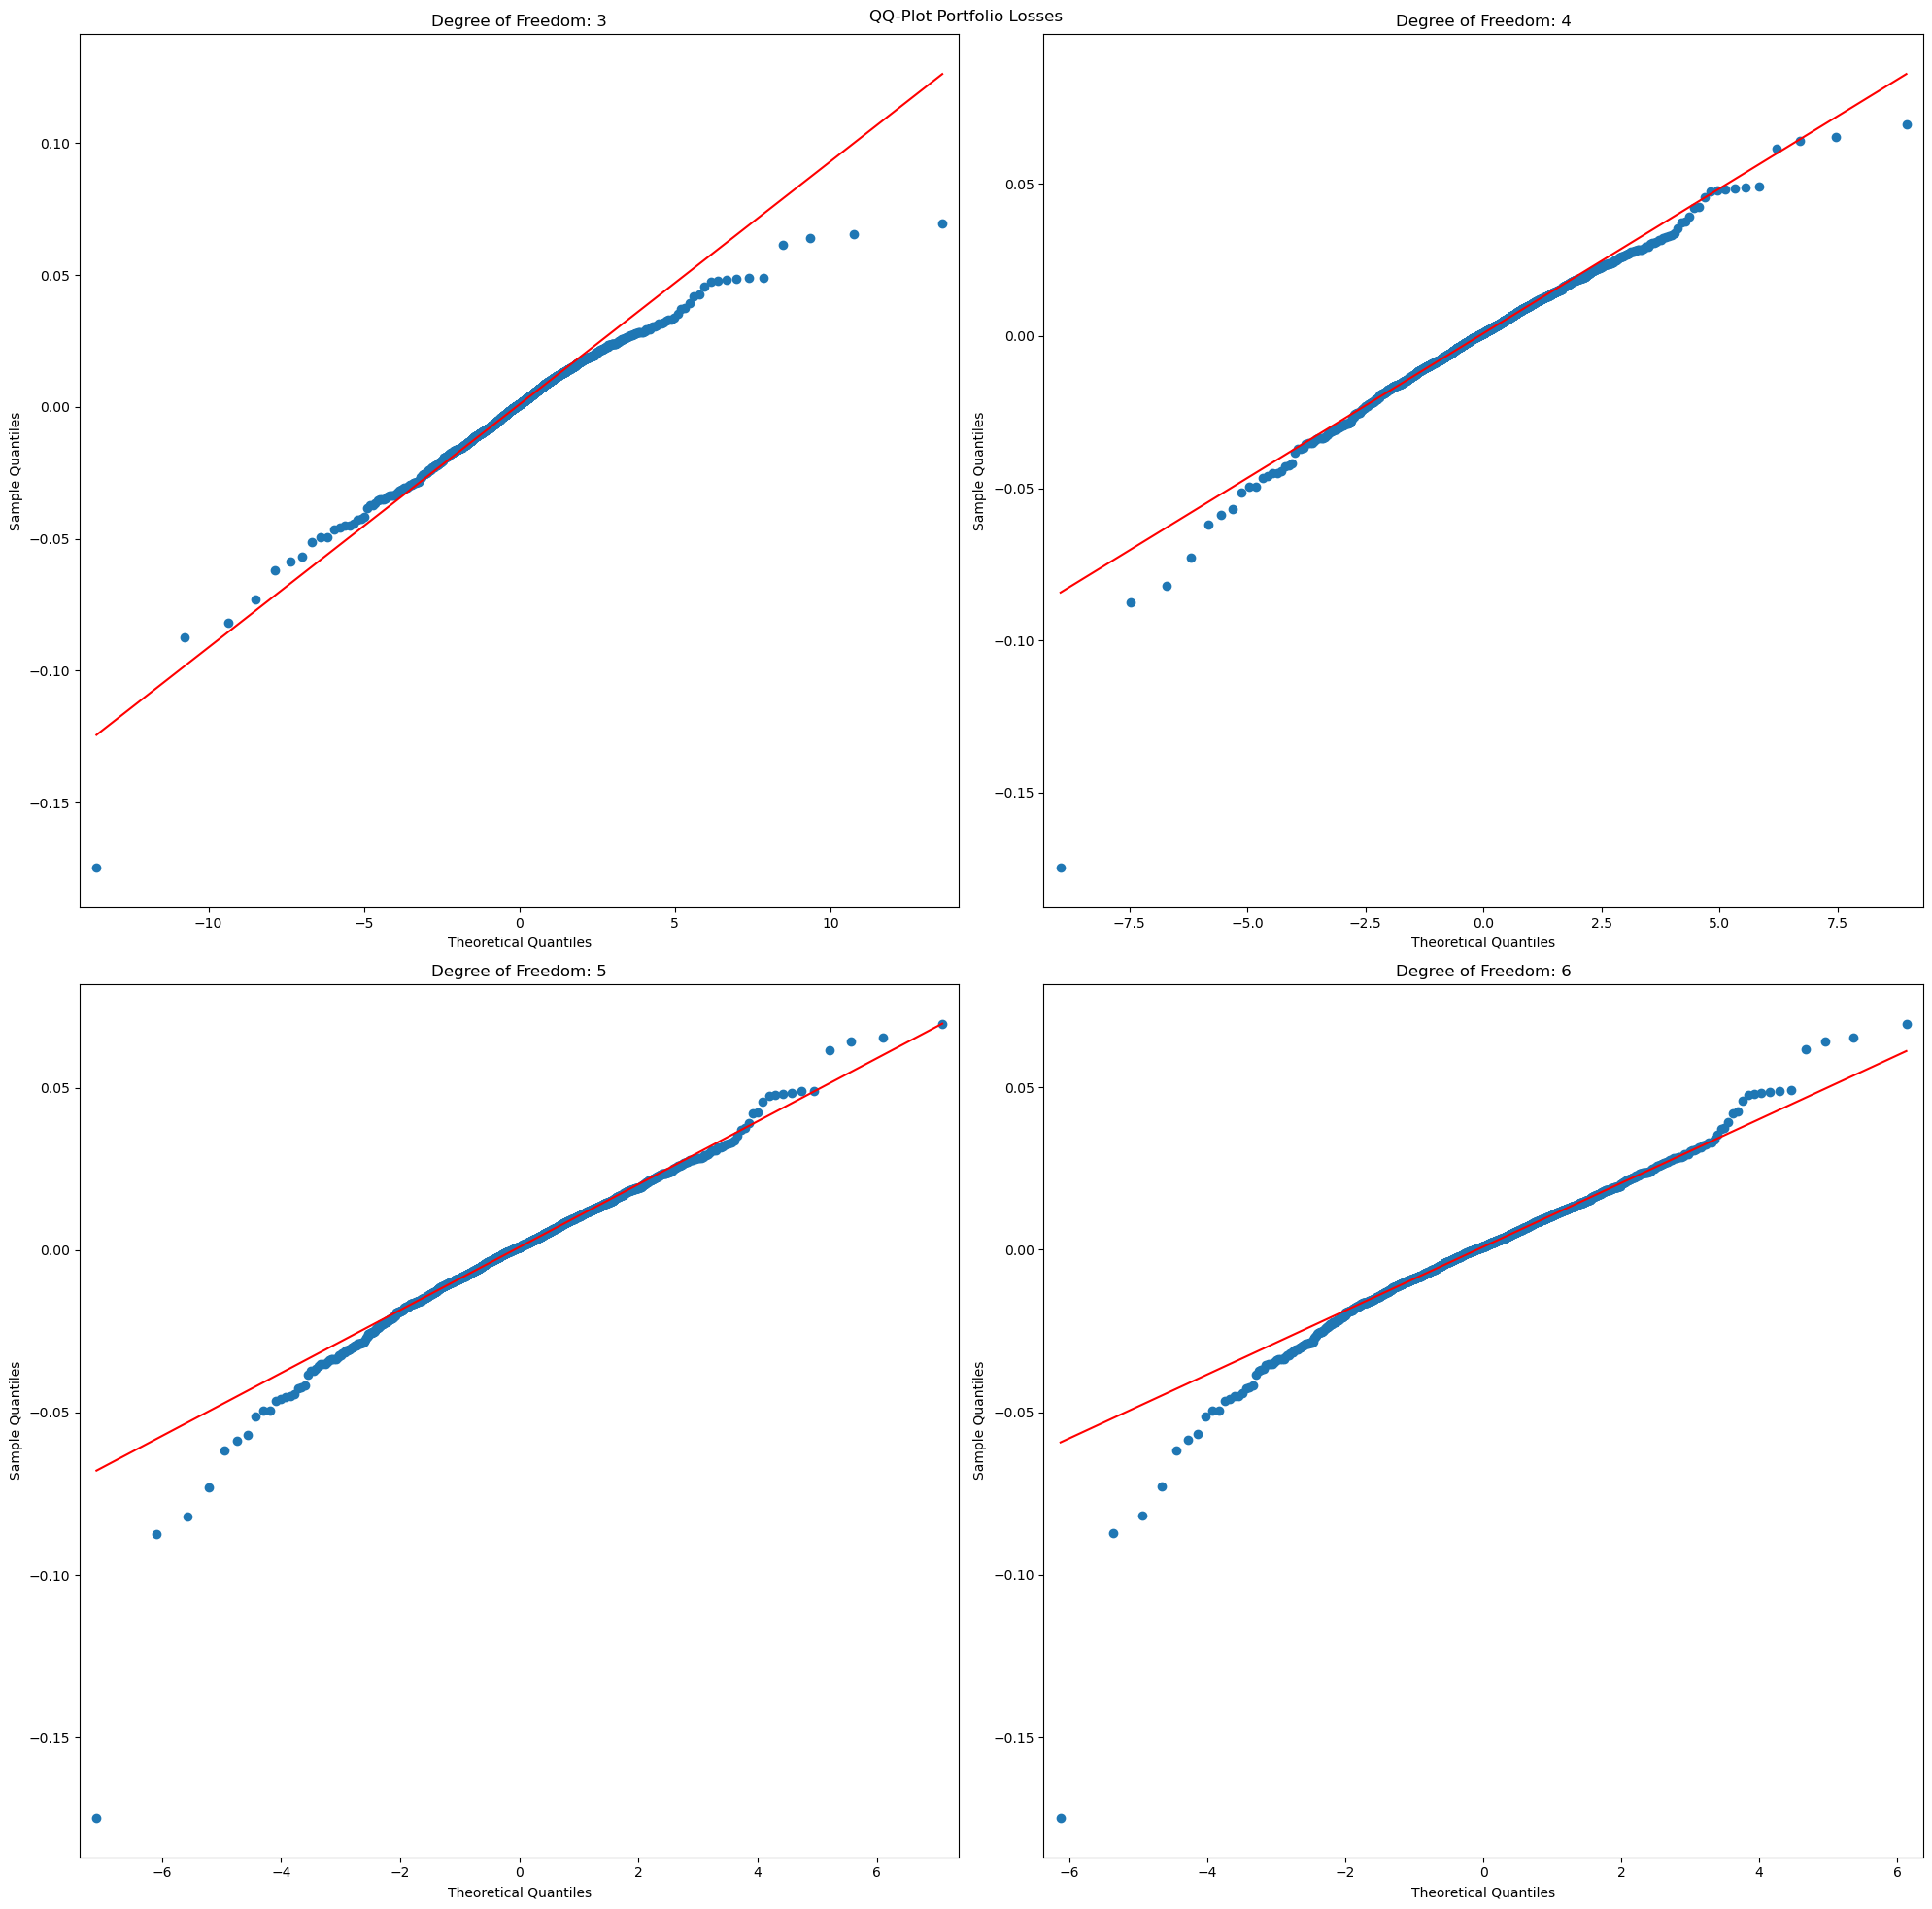

In [28]:
#QQ-plot of historical asset returns to assess validity of Student-t approximation
j = 1
fig = plt.figure(figsize=(20,20))
plt.suptitle("QQ-Plot Portfolio Losses")
for d in degrees_of_freedom:
    sm.qqplot(portfolio_weighted, dist=stats.t, distargs=(d,), line="q", ax=plt.subplot(2,2,j))
    plt.subplot(2,2,j).title.set_text('Degree of Freedom: ' + str(d))
    j += 1
plt.tight_layout()
plt.show()

# Backtest

In [29]:
def Backtest(VaR_975, VaR_99, ES_975, ES_99, Loss):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - Loss: Array of observed losses.
    - VaR_975: Array of VaR estimates at the 97.5% confidence level.
    - ES_975: Array of ES estimates at the 97.5% confidence level.
    - VaR_99: Array of VaR estimates at the 99% confidence level.
    - ES_99: Array of ES estimates at the 99% confidence level.

    Returns:
    NO RETURNS FOR NOW
    - tTest_ES_975: The t-test statistic for the ES at the 97.5% level.
    - ES_p975: The p-value associated with the t-test.
    - T_99: The t-test statistic for the ES at the 97.5% level.
    - ES_p99: The p-value associated with the t-test.
    """
    print()
    # Convert gains into losses to align with the conventional risk metrics perspective
    Loss = -1 * Loss

    # .975 Level

    # Identify periods where the actual loss exceeds the VaR thresholds
    Violations_VaR_975 = Loss > VaR_975
    # Show amount of violations
    print("VaR Violations .975: ", sum(Violations_VaR_975))

    # Calculate the mean loss where there are VaR_975 violations
    average_Real_ES_975 = np.mean(Loss[Violations_VaR_975])
    # Adjust ES_975 estimates for comparison, using VaR_975 violations as the reference
    average_Theoretical_ES_975 = np.mean(ES_975[Violations_VaR_975])
    print("Average ES .975 Real and Theoretical: ", average_Real_ES_975, average_Theoretical_ES_975)

    # Calculate the standard error of losses exceeding the VaR_975
    standard_error = np.std(Loss[Violations_VaR_975]) / np.sqrt(np.sum(Violations_VaR_975))
    # Compute the t-test statistic
    tTest_ES_975 = (average_Real_ES_975 - average_Theoretical_ES_975) / standard_error
    # Calculate the two-sided p-value from the t-test statistic
    ES_p975 = stats.norm.sf(abs(tTest_ES_975)) * 2
    print("t-Test significance of difference: ", ES_p975)

    # .99 Level
    Violations_VaR_99 = Loss > VaR_99
    # Show amount of violations
    print("VaR Violations .99: ", sum(Violations_VaR_99))

    # Calculate the mean loss where there are VaR_99 violations
    average_Real_ES_99 = np.mean(Loss[Violations_VaR_99])
    # Adjust ES_99 estimates for comparison, using VaR_99 violations as the reference
    average_Theoretical_ES_99 = np.mean(ES_99[Violations_VaR_99])
    print("Average ES .99 Real and Theoretical: ", average_Real_ES_99, average_Theoretical_ES_99)

    # Calculate the standard error of losses exceeding the VaR_99
    standard_error = np.std(Loss[Violations_VaR_99]) / np.sqrt(np.sum(Violations_VaR_99))
    # Compute the t-test statistic
    tTest_ES_99 = (average_Real_ES_99 - average_Theoretical_ES_99) / standard_error
    # Calculate the two-sided p-value from the t-test statistic
    ES_p99 = stats.norm.sf(abs(tTest_ES_99)) * 2
    print("t-Test significance of difference: ", ES_p99)

    return


In [30]:
# Backtest VaR
index = indexes_where_year_changes

# For each period we find amount of VaR violations
for i in range(len(index)-1):
    print()
    print(f'Variance Covariance Normal | period={i}')
    Backtest(VarCovN_VaR_975[index[i]:index[i+1]], VarCovN_VaR_99[index[i]:index[i+1]],
              VarCovN_ES_975[index[i]:index[i+1]], VarCovN_ES_99[index[i]:index[i+1]],
              portfolio_weighted[index[i]:index[i+1]])
    
for i in range(len(index)-1):
    for j in range(len(degrees_of_freedom)):
        print()
        print(f'Variance Covariance t-Student | period={i}, dof={j+3}')
        Backtest(VarCovT_VaR_975[index[i]:index[i+1], j], VarCovT_VaR_99[index[i]:index[i+1], j],
                VarCovT_ES_975[index[i]:index[i+1], j], VarCovT_ES_99[index[i]:index[i+1], j],
                portfolio_weighted[index[i]:index[i+1]])


Variance Covariance Normal | period=0

VaR Violations .975:  9
Average ES .975 Real and Theoretical:  0.028211222239538203 0.021208762993112973
t-Test significance of difference:  0.03261163901331736
VaR Violations .99:  8
Average ES .99 Real and Theoretical:  0.02939611798489499 0.023881369971892386
t-Test significance of difference:  0.11156957276886034

Variance Covariance Normal | period=1

VaR Violations .975:  2
Average ES .975 Real and Theoretical:  0.029707729350685507 0.02661037730420905
t-Test significance of difference:  0.03258009407836292
VaR Violations .99:  2
Average ES .99 Real and Theoretical:  0.029707729350685507 0.030082451521228334
t-Test significance of difference:  0.7959716577698586

Variance Covariance Normal | period=2

VaR Violations .975:  11
Average ES .975 Real and Theoretical:  0.030287475632506167 0.026904270884263223
t-Test significance of difference:  0.07776569555543504
VaR Violations .99:  8
Average ES .99 Real and Theoretical:  0.03300511980179101 

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_11128\3551210729.py:39: RuntimeWarning: divide by zero encountered in scalar divide
  tTest_ES_975 = (average_Real_ES_975 - average_Theoretical_ES_975) / standard_error
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_11128\3551210729.py:58: RuntimeWarning: divide by zero encountered in scalar divide
  tTest_ES_99 = (average_Real_ES_99 - average_Theoretical_ES_99) / standard_error
